In [ ]:
import pandas as pd

file = "data.xlsx"

df = pd.read_excel(file, sheet_name="Data - Part 3")


In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)
pd.set_option('display.expand_frame_repr', False)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19655 entries, 0 to 19654
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   install_date          19655 non-null  datetime64[ns]
 1   country_code          19655 non-null  object        
 2   platform              19655 non-null  object        
 3   Media Source          19655 non-null  object        
 4   Media Source Type     19655 non-null  object        
 5   Spend                 19655 non-null  float64       
 6   installs              19655 non-null  int64         
 7   retention_cnt_d1      17004 non-null  float64       
 8   retention_cnt_d3      16190 non-null  float64       
 9   retention_cnt_d7      15615 non-null  float64       
 10  retention_cnt_d30     14309 non-null  float64       
 11  retention_cnt_d60     13470 non-null  float64       
 12  iap_net_revenue_d0    19651 non-null  float64       
 13  iap_net_revenue_

In [ ]:
df.describe()

,install_date,Spend,installs,retention_cnt_d1,retention_cnt_d3,retention_cnt_d7,retention_cnt_d30,retention_cnt_d60,iap_net_revenue_d0,iap_net_revenue_d3,iap_net_revenue_d7,iap_net_revenue_d30,iap_net_revenue_d60,iap_net_revenue_d90,iap_net_revenue_d180,iap_net_revenue_d270,iap_net_revenue_d360,iap_net_revenue_d450,ad_revenue_d0,ad_revenue_d3,ad_revenue_d7,ad_revenue_d30,ad_revenue_d60,ad_revenue_d90,ad_revenue_d180,ad_revenue_d270,ad_revenue_d360,ad_revenue_d450
count,19655,19655.000000,19655.000000,17004.000000,16190.000000,15615.000000,14309.000000,13470.000000,19651.000000,19651.000000,19651.000000,19651.000000,19651.000000,19652.000000,19655.000000,19655.000000,18454.000000,13971.000000,19651.000000,19651.000000,19651.000000,19651.000000,19651.000000,19652.000000,19655.000000,19655.000000,18454.000000,13971.000000
mean,2022-08-29 23:57:52.520987136,1031.873168,367.416026,79.312691,52.394441,41.466923,24.768118,18.438530,11.636247,44.790510,82.177481,256.875313,440.238469,592.292739,924.663871,1182.167346,1389.092530,1156.426163,12.839888,27.641625,37.800148,67.435504,89.625201,104.392647,132.063961,149.538267,166.157092,160.683280
min,2022-01-01 00:00:00,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2022-05-11 00:00:00,0.000000,7.000000,5.000000,4.000000,3.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.064390,0.218357,0.265816,0.294378,0.330450,0.351492,0.364778,0.327743
50%,2022-09-04 00:00:00,115.123040,39.000000,15.000000,11.000000,9.000000,6.000000,5.000000,0.000000,2.086000,4.179000,11.165000,16.751000,20.258000,27.958000,33.523000,36.242500,28.602000,0.506160,1.123618,1.851290,4.072823,5.371137,6.148663,7.389626,7.973026,8.224341,7.074657
75%,2022-12-25 00:00:00,689.745800,164.000000,61.000000,42.000000,34.000000,23.000000,18.000000,6.979000,27.937000,50.974000,144.718000,234.255000,313.248250,487.515000,630.112000,717.627750,605.202500,3.773513,8.402354,12.376792,25.799996,35.652092,42.014883,54.116367,62.635688,67.798577,56.446313
max,2023-03-31 00:00:00,74903.416560,14076.000000,2070.000000,1561.000000,1396.000000,899.000000,756.000000,800.422000,2945.544000,4739.434000,15779.463000,26396.979000,40408.081000,66706.801000,90672.267000,118360.571000,50692.222000,944.997209,1988.121188,2590.581994,4251.142567,5296.724316,5928.106629,6681.017280,7003.738173,7322.382024,7487.403187
std,NaN,2707.749780,1076.809222,162.078970,104.745948,83.273836,50.538292,38.340113,33.200172,118.537018,215.344228,686.388177,1218.390593,1674.344846,2639.115807,3442.726776,4208.535189,3075.859399,37.918563,81.199326,108.579836,186.633461,246.053023,285.922153,361.308915,410.130897,458.211051,457.666043


CHECK DUPLICATES


In [ ]:
df.duplicated().sum()

np.int64(0)

MISSING DATA

In [ ]:
df.isna().sum()

,0
install_date,0
country_code,0
platform,0
Media Source,0
Media Source Type,0
Spend,0
installs,0
retention_cnt_d1,2651
retention_cnt_d3,3465
retention_cnt_d7,4040


Keep only paid UA rows and cohorts that have reached D360

In [ ]:


analysis_df = df[
    (df["Spend"] > 0) &
    (df["iap_net_revenue_d360"].notna()) &
    (df["ad_revenue_d360"].notna())
].copy()

print("Original rows:", len(df))
print("Rows used for analysis:", len(analysis_df))
print("Rows excluded:", len(df) - len(analysis_df))


Original rows: 19655
Rows used for analysis: 13661
Rows excluded: 5994


In [ ]:
analysis_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13661 entries, 1201 to 19654
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   install_date          13661 non-null  datetime64[ns]
 1   country_code          13661 non-null  object        
 2   platform              13661 non-null  object        
 3   Media Source          13661 non-null  object        
 4   Media Source Type     13661 non-null  object        
 5   Spend                 13661 non-null  float64       
 6   installs              13661 non-null  int64         
 7   retention_cnt_d1      11849 non-null  float64       
 8   retention_cnt_d3      11191 non-null  float64       
 9   retention_cnt_d7      10670 non-null  float64       
 10  retention_cnt_d30     9588 non-null   float64       
 11  retention_cnt_d60     8903 non-null   float64       
 12  iap_net_revenue_d0    13661 non-null  float64       
 13  iap_net_revenue_d3

In [ ]:
for day in [0, 3, 7, 360]:
    analysis_df[f"revenue_d{day}"] = (
        analysis_df[f"iap_net_revenue_d{day}"].fillna(0)
        + analysis_df[f"ad_revenue_d{day}"].fillna(0)
    )

    analysis_df[f"roas_d{day}"] = (
        analysis_df[f"revenue_d{day}"]
        / analysis_df["Spend"]
    )

Since we are only interested in ROAS values, we will keep only the relevant columns

In [ ]:
cols = [
    'country_code', 'platform', 'Media Source', 'Media Source Type',
    'install_date', 'Spend', 'revenue_d0', 'revenue_d3',
    'revenue_d7', 'revenue_d360', 'roas_d0', 'roas_d3',
    'roas_d7', 'roas_d360'
]

analysis_df = analysis_df[cols]

Keep cohorts that achieved 100%

In [ ]:
analysis_df["target_360"] = (
    analysis_df["roas_d360"] >= 1.0
).astype(int)

In [ ]:
analysis_df.head()

,country_code,platform,Media Source,Media Source Type,install_date,Spend,revenue_d0,revenue_d3,revenue_d7,revenue_d360,roas_d0,roas_d3,roas_d7,roas_d360,target_360
1201,DE,ios,Media_source_1,Media_source_type_1,2023-03-08,4717.06732,0.127419,0.863423,3.856933,4.207427,0.000027,0.000183,0.000818,0.000892,0
1203,DE,ios,Media_source_4,Media_source_type_2,2023-03-08,1295.13420,5.427563,28.179218,36.275904,1736.668100,0.004191,0.021758,0.028009,1.340917,1
1206,NL,android,Media_source_7,Media_source_type_4,2023-03-08,72.44812,0.168588,0.657713,0.814020,134.905088,0.002327,0.009078,0.011236,1.862092,1
1208,UK,ios,Media_source_7,Media_source_type_4,2023-03-08,437.66604,0.031190,0.590064,0.640784,0.896392,0.000071,0.001348,0.001464,0.002048,0
1209,UK,android,Media_source_1,Media_source_type_1,2023-03-08,8.93196,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0


In [ ]:
print(analysis_df["target_360"].value_counts())

target_360
0    10872
1     2789
Name: count, dtype: int64


In [ ]:
print(
    "D360 success rate:",
    analysis_df["target_360"].mean()
)

D360 success rate: 0.20415782153575873


20% of the chorots achived 100%

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define thresholds from 0% to 100%, in increments of 5%
thresholds = np.arange(0, 1.01, 0.05)

# ROAS columns to analyze
roas_columns = ["roas_d0", "roas_d3", "roas_d7"]

# Store results separately
results = {}

for col in roas_columns:
    rows = []

    for threshold in thresholds:
        # Filter cohorts meeting the ROAS threshold
        group = analysis_df[analysis_df[col] >= threshold]

        total_spend = group["Spend"].sum()

        if not group.empty and total_spend > 0:
            rows.append({
                "threshold": threshold * 100,
                "cohorts": len(group),
                "total_spend": total_spend,
                "success_rate": (
                    (group["Spend"] * group["target_360"]).sum()
                    / total_spend
                ) * 100
            })

    # Create a separate DataFrame for each ROAS day
    day = col[5:]  # d0, d3, d7

    results[f"{day}_threshold_results"] = pd.DataFrame(rows)

# Assign separate DataFrames
d0_threshold_results = results["d0_threshold_results"]
d3_threshold_results = results["d3_threshold_results"]
d7_threshold_results = results["d7_threshold_results"]

# Display results
print("D0 Threshold Results:")
print(d0_threshold_results.to_string(index=False))

print("\nD3 Threshold Results:")
print(d3_threshold_results.to_string(index=False))

print("\nD7 Threshold Results:")
print(d7_threshold_results.to_string(index=False))


D0 Threshold Results:
 threshold  cohorts  total_spend  success_rate
       0.0    13661 1.880180e+07     36.176629
       5.0      791 7.654382e+05     72.096506
      10.0      241 8.193982e+04     78.002519
      15.0      122 1.617578e+04     64.126634
      20.0       83 4.966170e+03     71.942446
      25.0       66 3.176800e+03     69.009684
      30.0       55 2.647830e+03     76.086957
      35.0       46 2.101988e+03     80.878187
      40.0       39 1.755626e+03     91.011871
      45.0       34 1.563093e+03     94.412698
      50.0       29 1.191920e+03     94.587843
      55.0       28 9.110599e+02     92.919390
      60.0       24 8.018915e+02     92.574257
      65.0       22 7.423451e+02     95.855615
      70.0       20 5.895094e+02     94.781145
      75.0       15 5.081293e+02    100.000000
      80.0       14 4.803410e+02    100.000000
      85.0       13 3.463616e+02    100.000000
      90.0       13 3.463616e+02    100.000000
      95.0       13 3.463616e+02    10

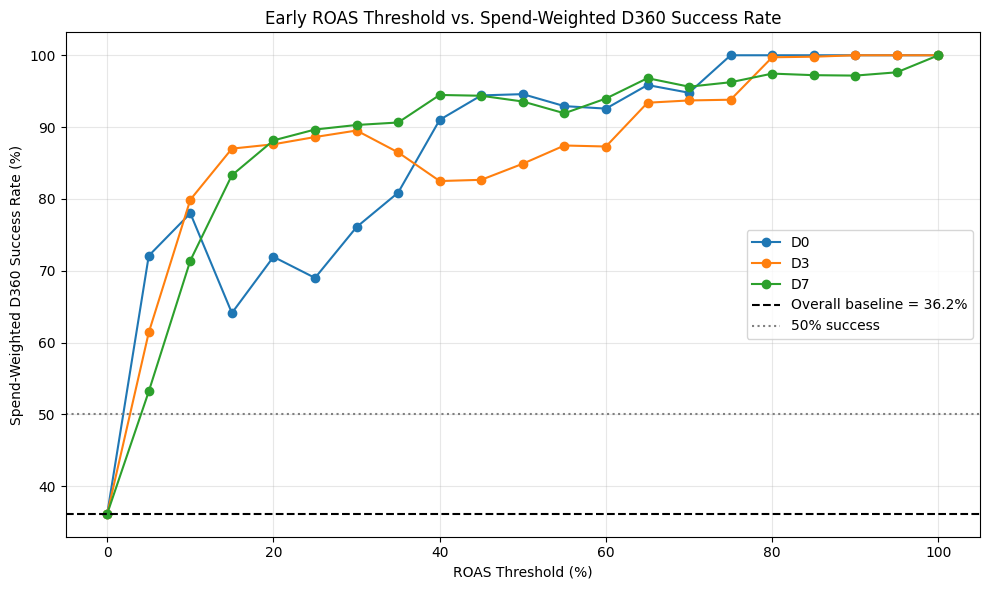

In [ ]:

import matplotlib.pyplot as plt

# Overall spend-weighted baseline
baseline = (
    (analysis_df["Spend"] * analysis_df["target_360"]).sum()
    / analysis_df["Spend"].sum()
) * 100

plt.figure(figsize=(10, 6))

# D0
plt.plot(
    d0_threshold_results["threshold"],
    d0_threshold_results["success_rate"],
    marker="o",
    label="D0"
)

# D3
plt.plot(
    d3_threshold_results["threshold"],
    d3_threshold_results["success_rate"],
    marker="o",
    label="D3"
)

# D7
plt.plot(
    d7_threshold_results["threshold"],
    d7_threshold_results["success_rate"],
    marker="o",
    label="D7"
)

# Overall spend-weighted baseline
plt.axhline(
    baseline,
    linestyle="--",
    color="black",
    label=f"Overall baseline = {baseline:.1f}%"
)

# 50% success reference
plt.axhline(
    50,
    linestyle=":",
    color="gray",
    label="50% success"
)

plt.xlabel("ROAS Threshold (%)")
plt.ylabel("Spend-Weighted D360 Success Rate (%)")

plt.title(
    "Early ROAS Threshold vs. Spend-Weighted D360 Success Rate"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Key findings
- D7 is the strongest early indicator of D360 success in your data.
- Overall spend-weighted success rate is 36.18%.
- At a 40% ROAS threshold:
  - D0: 91.01% success, 39 cohorts.
  - D3: 82.49% success, 156 cohorts.
  - D7: 94.48% success, 326 cohorts.
- Higher thresholds increase success rates but reduce the number of qualifying cohorts and the spend retained.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

thresholds = np.arange(0, 1.01, 0.05)

results = []

for threshold in thresholds:
    group = analysis_df[analysis_df["roas_d7"] >= threshold]

    if len(group) > 0:
        results.append({
            "d7_threshold": threshold * 100,
            "cohorts": len(group),
            "success_rate": group["target_360"].mean() * 100
        })

threshold_results = pd.DataFrame(results)

print(threshold_results)

    d7_threshold  cohorts  success_rate
0            0.0    13661     20.415782
1            5.0     4720     46.610169
2           10.0     2588     59.582689
3           15.0     1553     67.095943
4           20.0     1006     71.471173
5           25.0      712     73.735955
6           30.0      533     75.984991
7           35.0      423     77.304965
8           40.0      326     80.368098
9           45.0      269     82.527881
10          50.0      220     84.090909
11          55.0      195     84.615385
12          60.0      182     86.263736
13          65.0      164     88.414634
14          70.0      149     89.261745
15          75.0      134     91.791045
16          80.0      116     95.689655
17          85.0      107     96.261682
18          90.0       96     97.916667
19          95.0       88     98.863636
20         100.0       82    100.000000


In [ ]:
thresholds = np.arange(0, 1.01, 0.05)

d0_results = []

for threshold in thresholds:
    group = analysis_df[analysis_df["roas_d0"] >= threshold]

    if len(group) > 0:
        d0_results.append({
            "d0_threshold": threshold * 100,
            "cohorts": len(group),
            "success_rate": group["target_360"].mean() * 100
        })

d0_threshold_results = pd.DataFrame(d0_results)

print(d0_threshold_results)

    d0_threshold  cohorts  success_rate
0            0.0    13661     20.415782
1            5.0      791     59.165613
2           10.0      241     60.995851
3           15.0      122     66.393443
4           20.0       83     67.469880
5           25.0       66     69.696970
6           30.0       55     72.727273
7           35.0       46     73.913043
8           40.0       39     76.923077
9           45.0       34     82.352941
10          50.0       29     86.206897
11          55.0       28     85.714286
12          60.0       24     87.500000
13          65.0       22     90.909091
14          70.0       20     90.000000
15          75.0       15    100.000000
16          80.0       14    100.000000
17          85.0       13    100.000000
18          90.0       13    100.000000
19          95.0       13    100.000000
20         100.0       13    100.000000


In [ ]:
thresholds = np.arange(0, 1.01, 0.05)

d3_results = []

for threshold in thresholds:
    group = analysis_df[analysis_df["roas_d3"] >= threshold]

    if len(group) > 0:
        d3_results.append({
            "d3_threshold": threshold * 100,
            "cohorts": len(group),
            "success_rate": group["target_360"].mean() * 100
        })

d3_threshold_results = pd.DataFrame(d3_results)

print(d3_threshold_results)

    d3_threshold  cohorts  success_rate
0            0.0    13661     20.415782
1            5.0     3194     51.095805
2           10.0     1398     63.876967
3           15.0      708     68.502825
4           20.0      447     70.693512
5           25.0      319     71.473354
6           30.0      245     73.061224
7           35.0      185     76.216216
8           40.0      156     78.846154
9           45.0      131     80.916031
10          50.0      116     81.896552
11          55.0       98     82.653061
12          60.0       92     82.608696
13          65.0       83     84.337349
14          70.0       76     85.526316
15          75.0       64     90.625000
16          80.0       55     96.363636
17          85.0       51     98.039216
18          90.0       46    100.000000
19          95.0       44    100.000000
20         100.0       43    100.000000


In [ ]:
import matplotlib.pyplot as plt

baseline = analysis_df["target_360"].mean() * 100

plt.figure(figsize=(10, 6))

plt.plot(
    d0_threshold_results["d0_threshold"],
    d0_threshold_results["success_rate"],
    marker="o",
    label="D0"
)

plt.plot(
    d3_threshold_results["d3_threshold"],
    d3_threshold_results["success_rate"],
    marker="o",
    label="D3"
)

plt.plot(
    threshold_results["d7_threshold"],
    threshold_results["success_rate"],
    marker="o",
    label="D7"
)

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Overall baseline = {baseline:.1f}%"
)

plt.axhline(
    50,
    linestyle="--",
    label="50% success"
)

plt.xlabel("ROAS Threshold (%)")
plt.ylabel("Historical D360 Success Rate (%)")
plt.title("Early ROAS Threshold vs. D360 Target Achievement")
plt.legend()
plt.grid(True)

plt.show()

KeyError: 'd0_threshold'

<Figure size 1000x600 with 0 Axes>

In [ ]:

import numpy as np
import pandas as pd

thresholds = np.arange(0, 1.01, 0.05)

results = []

for day in [0, 3, 7]:
    roas_col = f"roas_d{day}"

    for threshold in thresholds:
        group = analysis_df[analysis_df[roas_col] >= threshold]

        if len(group) > 0:
            results.append({
                "threshold_pct": threshold * 100,
                "day": f"D{day}",
                "success_rate_pct": group["target_360"].mean() * 100,
                "cohorts": len(group)
            })

threshold_results = pd.DataFrame(results)

# Pivot success rates
success_table = threshold_results.pivot(
    index="threshold_pct",
    columns="day",
    values="success_rate_pct"
).reindex(columns=["D0", "D3", "D7"])

# Pivot cohort counts
cohort_table = threshold_results.pivot(
    index="threshold_pct",
    columns="day",
    values="cohorts"
).reindex(columns=["D0", "D3", "D7"])

# Combine both metrics into one table
final_table = pd.concat(
    {"Success Rate (%)": success_table,
     "Number of Cohorts": cohort_table},
    axis=1
)

final_table.index.name = "ROAS Threshold (%)"

print(final_table.round(2).to_string())


                   Success Rate (%)                 Number of Cohorts              
day                              D0      D3      D7                D0     D3     D7
ROAS Threshold (%)                                                                 
0.0                           20.42   20.42   20.42             13661  13661  13661
5.0                           59.17   51.10   46.61               791   3194   4720
10.0                          61.00   63.88   59.58               241   1398   2588
15.0                          66.39   68.50   67.10               122    708   1553
20.0                          67.47   70.69   71.47                83    447   1006
25.0                          69.70   71.47   73.74                66    319    712
30.0                          72.73   73.06   75.98                55    245    533
35.0                          73.91   76.22   77.30                46    185    423
40.0                          76.92   78.85   80.37                39    156

In [ ]:

# Compare D360 outcomes across individual dimensions

dimensions = [
    "platform",
    "country_code",
    "Media Source Type",
    "Media Source"
]

segment_results = []

for dimension in dimensions:
    summary = (
        analysis_df.groupby(dimension, dropna=False)
        .agg(
            cohorts=("target_360", "size"),
            total_spend=("Spend", "sum"),
            success_rate=("target_360", "mean"),
            total_revenue_d360=("revenue_d360", "sum")
        )
        .reset_index()
    )

    summary["dimension"] = dimension

    summary["success_rate_pct"] = (
        summary["success_rate"] * 100
    )

    summary["d360_roas_pct"] = (
        summary["total_revenue_d360"]
        / summary["total_spend"] * 100
    )

    segment_results.append(summary)

segment_table = pd.concat(
    segment_results,
    ignore_index=True
)

print(
    segment_table[
        [
            "dimension",
            "platform",
            "country_code",
            "Media Source Type",
            "Media Source",
            "cohorts",
            "total_spend",
            "success_rate_pct",
            "d360_roas_pct"
        ]
    ].round(2).to_string(index=False)
)


        dimension platform country_code   Media Source Type   Media Source  cohorts  total_spend  success_rate_pct  d360_roas_pct
         platform  android          NaN                 NaN            NaN     8793  14549932.59             26.18         112.93
         platform      ios          NaN                 NaN            NaN     4868   4251864.05             10.00          44.05
     country_code      NaN           CA                 NaN            NaN     2538    432620.48             11.54          59.24
     country_code      NaN           DE                 NaN            NaN     2802   5077199.98             24.80         111.44
     country_code      NaN           NL                 NaN            NaN     2119    857324.26             10.24          71.05
     country_code      NaN           UK                 NaN            NaN     2651   1138293.94             14.11          46.28
     country_code      NaN           US                 NaN            NaN     3551  11296

In [ ]:

def segmented_threshold_table(
    df,
    dimension,
    min_cohorts=30
):
    thresholds = np.arange(0, 1.01, 0.05)
    results = []

    for segment_value, segment_df in df.groupby(
        dimension, dropna=False
    ):
        for day in [0, 3, 7]:
            roas_col = f"roas_d{day}"

            for threshold in thresholds:
                group = segment_df[
                    segment_df[roas_col] >= threshold
                ]

                if len(group) < min_cohorts:
                    continue

                results.append({
                    dimension: segment_value,
                    "threshold_pct": threshold * 100,
                    "day": f"D{day}",
                    "cohorts": len(group),
                    "success_rate_pct":
                        group["target_360"].mean() * 100
                })

    results_df = pd.DataFrame(results)

    if results_df.empty:
        return results_df

    return results_df.sort_values(
        [dimension, "threshold_pct", "day"]
    )


platform_results = segmented_threshold_table(
    analysis_df,
    dimension="platform",
    min_cohorts=30
)

print(platform_results.round(2).to_string(index=False))


platform  threshold_pct day  cohorts  success_rate_pct
 android            0.0  D0     8793             26.18
 android            0.0  D3     8793             26.18
 android            0.0  D7     8793             26.18
 android            5.0  D0      665             58.80
 android            5.0  D3     2767             50.20
 android            5.0  D7     4094             45.70
 android           10.0  D0      186             59.68
 android           10.0  D3     1140             62.81
 android           10.0  D7     2181             58.73
 android           15.0  D0       92             66.30
 android           15.0  D3      557             67.50
 android           15.0  D7     1254             66.43
 android           20.0  D0       62             67.74
 android           20.0  D3      347             70.03
 android           20.0  D7      790             70.76
 android           25.0  D0       50             70.00
 android           25.0  D3      241             71.37
 android  

In [ ]:
def segment_analysis(df, column, threshold=0.20):
    result = (
        df[df["roas_d7"] >= threshold]
        .groupby(column)
        .agg(
            cohorts=("target_360", "size"),
            success_rate=("target_360", "mean")
        )
    )

    result["success_rate"] *= 100

    return result.sort_values("cohorts", ascending=False)

In [ ]:
print("PLATFORM")
print(segment_analysis(analysis_df, "platform"))

print("\nCOUNTRY")
print(segment_analysis(analysis_df, "country_code"))

print("\nMEDIA SOURCE")
print(segment_analysis(analysis_df, "Media Source"))

PLATFORM
          cohorts  success_rate
platform                       
android       790     70.759494
ios           216     74.074074

COUNTRY
              cohorts  success_rate
country_code                       
US                412     80.097087
CA                175     54.857143
DE                163     70.552147
UK                151     67.549669
NL                105     72.380952

MEDIA SOURCE
                cohorts  success_rate
Media Source                         
Media_source_6      180     65.555556
Media_source_3      179     84.916201
Media_source_7      164     70.731707
Media_source_1      161     65.838509
Media_source_5      125     68.000000
Media_source_4      107     69.158879
Media_source_2       90     75.555556


In [ ]:
# Platform-level threshold analysis
platform_results = []

thresholds = np.arange(0, 1.01, 0.05)

for platform in analysis_df["platform"].dropna().unique():

    platform_df = analysis_df[analysis_df["platform"] == platform]

    for day in [0, 3, 7]:

        roas_col = f"roas_d{day}"

        for threshold in thresholds:

            group = platform_df[platform_df[roas_col] >= threshold]

            if len(group) > 0:
                platform_results.append({
                    "platform": platform,
                    "day": f"D{day}",
                    "threshold": threshold * 100,
                    "cohorts": len(group),
                    "success_rate": group["target_360"].mean() * 100
                })

platform_threshold_results = pd.DataFrame(platform_results)

print(platform_threshold_results)

    platform day  threshold  cohorts  success_rate
0        ios  D0        0.0     4868     10.004108
1        ios  D0        5.0      126     61.111111
2        ios  D0       10.0       55     65.454545
3        ios  D0       15.0       30     66.666667
4        ios  D0       20.0       21     66.666667
..       ...  ..        ...      ...           ...
121  android  D7       80.0       85     95.294118
122  android  D7       85.0       78     96.153846
123  android  D7       90.0       69     97.101449
124  android  D7       95.0       62     98.387097
125  android  D7      100.0       57    100.000000

[126 rows x 5 columns]


In [ ]:
platform_benchmarks = []

for platform in platform_threshold_results["platform"].unique():

    for day in ["D0", "D3", "D7"]:

        temp = platform_threshold_results[
            (platform_threshold_results["platform"] == platform) &
            (platform_threshold_results["day"] == day) &
            (platform_threshold_results["success_rate"] > 50)
        ].sort_values("threshold")

        if len(temp) > 0:
            first = temp.iloc[0]

            platform_benchmarks.append({
                "platform": platform,
                "day": day,
                "benchmark": first["threshold"],
                "success_rate": first["success_rate"],
                "cohorts": first["cohorts"]
            })

platform_benchmarks = pd.DataFrame(platform_benchmarks)

print(platform_benchmarks)

  platform day  benchmark  success_rate  cohorts
0      ios  D0        5.0     61.111111      126
1      ios  D3        5.0     56.908665      427
2      ios  D7        5.0     52.555911      626
3  android  D0        5.0     58.796992      665
4  android  D3        5.0     50.198771     2767
5  android  D7       10.0     58.734525     2181


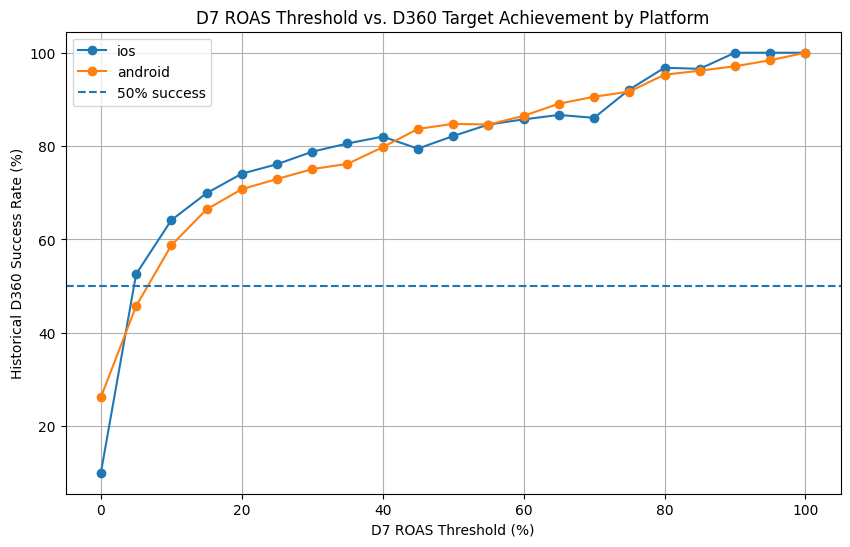

In [ ]:
plt.figure(figsize=(10, 6))

for platform in platform_threshold_results["platform"].unique():

    temp = platform_threshold_results[
        (platform_threshold_results["platform"] == platform) &
        (platform_threshold_results["day"] == "D7")
    ]

    plt.plot(
        temp["threshold"],
        temp["success_rate"],
        marker="o",
        label=platform
    )

plt.axhline(50, linestyle="--", label="50% success")

plt.xlabel("D7 ROAS Threshold (%)")
plt.ylabel("Historical D360 Success Rate (%)")
plt.title("D7 ROAS Threshold vs. D360 Target Achievement by Platform")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print(analysis_df["platform"].value_counts())

platform
android    8793
ios        4868
Name: count, dtype: int64


In [ ]:
thresholds = np.arange(0, 0.21, 0.01)

platform_results = []

for platform in analysis_df["platform"].unique():
    platform_df = analysis_df[analysis_df["platform"] == platform]

    for threshold in thresholds:
        group = platform_df[platform_df["roas_d7"] >= threshold]

        if len(group) > 0:
            platform_results.append({
                "platform": platform,
                "d7_threshold": threshold * 100,
                "cohorts": len(group),
                "success_rate": group["target_360"].mean() * 100
            })

platform_d7_results = pd.DataFrame(platform_results)

print(platform_d7_results)

   platform  d7_threshold  cohorts  success_rate
0       ios           0.0     4868     10.004108
1       ios           1.0     1510     28.410596
2       ios           2.0     1071     37.535014
3       ios           3.0      853     42.907386
4       ios           4.0      724     48.342541
5       ios           5.0      626     52.555911
6       ios           6.0      570     56.140351
7       ios           7.0      523     58.508604
8       ios           8.0      482     60.995851
9       ios           9.0      442     62.217195
10      ios          10.0      407     64.127764
11      ios          11.0      382     65.445026
12      ios          12.0      358     66.480447
13      ios          13.0      340     67.647059
14      ios          14.0      315     68.888889
15      ios          15.0      299     69.899666
16      ios          16.0      283     70.318021
17      ios          17.0      265     71.698113
18      ios          18.0      252     72.619048
19      ios         

In [ ]:
thresholds = np.arange(0, 0.21, 0.01)

platform_early_results = []

for platform in analysis_df["platform"].unique():
    platform_df = analysis_df[analysis_df["platform"] == platform]

    for day in [0, 3]:
        for threshold in thresholds:
            group = platform_df[
                platform_df[f"roas_d{day}"] >= threshold
            ]

            if len(group) > 0:
                platform_early_results.append({
                    "platform": platform,
                    "day": f"D{day}",
                    "threshold": threshold * 100,
                    "cohorts": len(group),
                    "success_rate": group["target_360"].mean() * 100
                })

platform_early_results = pd.DataFrame(platform_early_results)

print(platform_early_results)

   platform day  threshold  cohorts  success_rate
0       ios  D0        0.0     4868     10.004108
1       ios  D0        1.0      552     45.652174
2       ios  D0        2.0      342     53.801170
3       ios  D0        3.0      228     58.333333
4       ios  D0        4.0      164     59.756098
..      ...  ..        ...      ...           ...
79  android  D3       16.0      503     68.389662
80  android  D3       17.0      453     69.536424
81  android  D3       18.0      413     69.007264
82  android  D3       19.0      376     70.212766
83  android  D3       20.0      347     70.028818

[84 rows x 5 columns]


In [ ]:
platform_benchmarks = (
    platform_early_results[
        platform_early_results["success_rate"] > 50
    ]
    .sort_values(["platform", "day", "threshold"])
    .groupby(["platform", "day"], as_index=False)
    .first()
)

print(platform_benchmarks)

  platform day  threshold  cohorts  success_rate
0  android  D0        3.0     1487     50.168124
1  android  D3        5.0     2767     50.198771
2      ios  D0        2.0      342     53.801170
3      ios  D3        4.0      490     54.489796


In [ ]:
from scipy.stats import chi2_contingency

platform_target_table = pd.crosstab(
    analysis_df["platform"],
    analysis_df["target_360"]
)

print(platform_target_table)

chi2, p_value, dof, expected = chi2_contingency(
    platform_target_table
)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.6f}")

target_360     0     1
platform              
android     6491  2302
ios         4381   487
Chi-square statistic: 503.60
p-value: 0.000000
